# Consumption and temperature

How French electricity consumption depends on temperature, using a
national temperature built from ten cities.

## Key findings

- Consumption depends strongly on temperature below about 16 °C,
  because of electric heating: about 2300 MW per degree colder.
- Above about 25 °C, consumption rises slightly with air conditioning.
- Weekends follow the same relationship, about 10000 MW lower.
- 2013, the year with the highest consumption, was also the coldest.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from load_forecast.db import read_sql

plt.rcParams["figure.dpi"] = 80


daily_consumption = read_sql(
    """
    SELECT (ts AT TIME ZONE 'Europe/Paris')::date AS day,
           avg(consumption_mw) AS consumption_mw,
           count(consumption_mw) AS n_values
    FROM consumption
    GROUP BY day
    ORDER BY day
    """
)
daily_temperature = read_sql(
    """
    SELECT (ts AT TIME ZONE 'Europe/Paris')::date AS day,
           avg(temperature_c) AS temperature_c
    FROM weather
    GROUP BY day
    ORDER BY day
    """
)
daily_consumption.head()

,day,consumption_mw,n_values
0,2012-01-01,51194.826086956522,46
1,2012-01-02,60683.645833333333,48
2,2012-01-03,67762.104166666667,48
3,2012-01-04,68029.229166666667,48
4,2012-01-05,69157.395833333333,48


In [2]:
daily = daily_consumption.merge(daily_temperature, on="day")
daily = daily[daily["n_values"] >= 46]
daily["consumption_mw"] = daily["consumption_mw"].astype(float)
daily["temperature_c"] = daily["temperature_c"].astype(float)
print(daily.shape)
daily.head()

(5398, 4)


,day,consumption_mw,n_values,temperature_c
0,2012-01-01,51194.826087,46,11.456522
1,2012-01-02,60683.645833,48,8.772083
2,2012-01-03,67762.104167,48,8.766250
3,2012-01-04,68029.229167,48,8.473333
4,2012-01-05,69157.395833,48,9.372500


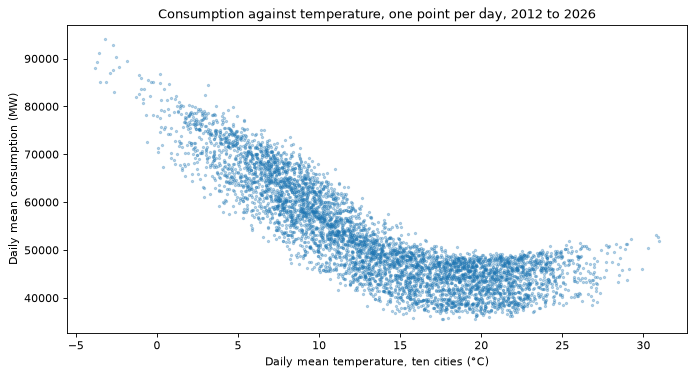

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(daily["temperature_c"], daily["consumption_mw"], s=4, alpha=0.3)
ax.set_xlabel("Daily mean temperature, ten cities (°C)")
ax.set_ylabel("Daily mean consumption (MW)")
ax.set_title("Consumption against temperature, one point per day, 2012 to 2026")
plt.show()

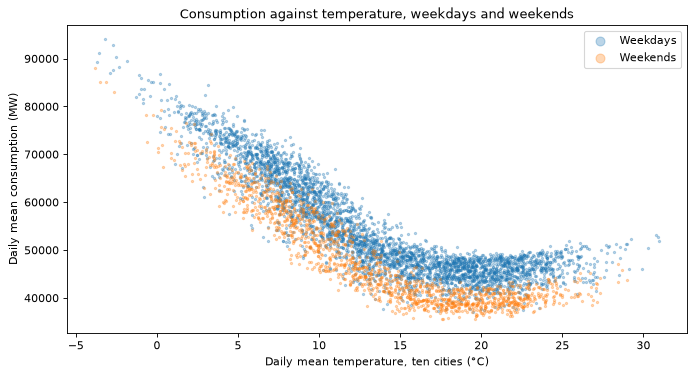

In [4]:
daily["day"] = pd.to_datetime(daily["day"])
daily["is_weekend"] = daily["day"].dt.dayofweek >= 5

fig, ax = plt.subplots(figsize=(10, 5))
for is_weekend, label in [(False, "Weekdays"), (True, "Weekends")]:
    subset = daily[daily["is_weekend"] == is_weekend]
    ax.scatter(subset["temperature_c"], subset["consumption_mw"], s=4, alpha=0.3, label=label)
ax.set_xlabel("Daily mean temperature, ten cities (°C)")
ax.set_ylabel("Daily mean consumption (MW)")
ax.set_title("Consumption against temperature, weekdays and weekends")
ax.legend(markerscale=4)
plt.show()

## Shape of the relationship

Consumption is highest on cold days, driven by electric heating, and
decreases as temperature rises up to about 16 °C. Above about 25 °C it
increases slightly, likely because of air conditioning. Between these
two temperatures, temperature has little effect.

Weekends follow the same shape, about 10,000 MW lower than weekdays.

In [5]:
threshold = 16
cold_weekdays = daily[(daily["temperature_c"] < threshold) & ~daily["is_weekend"]]

slope, intercept = np.polyfit(cold_weekdays["temperature_c"], cold_weekdays["consumption_mw"], 1)
print(f"{len(cold_weekdays)} cold weekdays")
print(f"Slope: {slope:.0f} MW per °C")

2421 cold weekdays
Slope: -2336 MW per °C


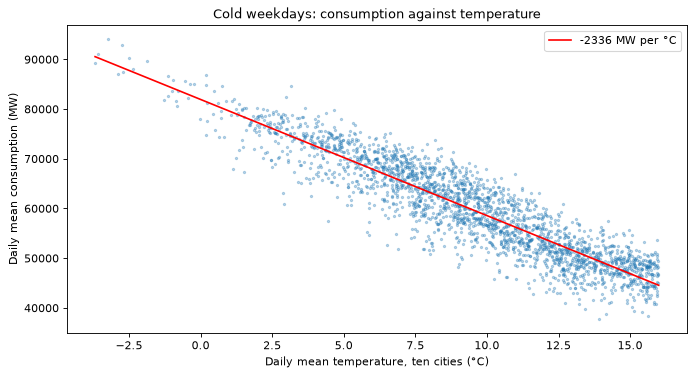

In [6]:
x = np.linspace(cold_weekdays["temperature_c"].min(), threshold, 50)

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(cold_weekdays["temperature_c"], cold_weekdays["consumption_mw"], s=4, alpha=0.3)
ax.plot(x, slope * x + intercept, color="red", label=f"{slope:.0f} MW per °C")
ax.set_xlabel("Daily mean temperature, ten cities (°C)")
ax.set_ylabel("Daily mean consumption (MW)")
ax.set_title("Cold weekdays: consumption against temperature")
ax.legend()
plt.show()

## Temperature sensitivity

On weekdays colder than 16 °C, consumption increases by about 2300 MW
for each degree of temperature drop.

In [7]:
daily["year"] = daily["day"].dt.year
yearly = daily[daily["year"] < 2026].groupby("year")[["consumption_mw", "temperature_c"]].mean()
yearly.round(1)

,consumption_mw,temperature_c
year,,
2012,55396.0,12.7
2013,56185.2,12.3
2014,52779.4,13.6
2015,54012.9,13.4
2016,54681.2,13.1
2017,54685.2,13.1
2018,54283.0,13.7
2019,53707.3,13.4
2020,50840.6,13.9


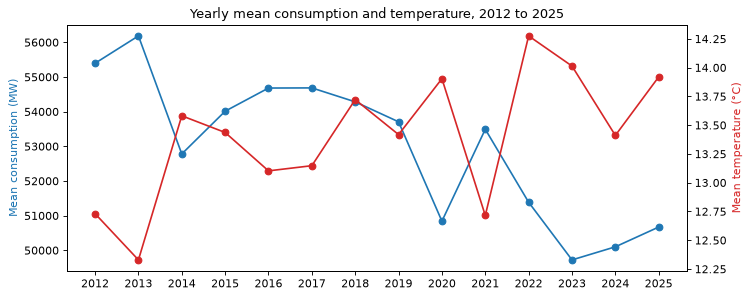

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(yearly.index, yearly["consumption_mw"], marker="o", color="tab:blue")
ax.set_ylabel("Mean consumption (MW)", color="tab:blue")
ax.set_xticks(yearly.index)

ax2 = ax.twinx()
ax2.plot(yearly.index, yearly["temperature_c"], marker="o", color="tab:red")
ax2.set_ylabel("Mean temperature (°C)", color="tab:red")
# ax2.invert_yaxis()

ax.set_title("Yearly mean consumption and temperature, 2012 to 2025")
plt.show()

## Year-to-year variations

As expected, colder years tend to have higher consumption: 2013 was
both the coldest year and the one with the highest consumption. It also seems that during lockdown in 2020, the temperature decreased, probably due to less human activity in big cities.